# Supervised Machine Learning 
###  Tutorial on Data Preprocessing, Regression and Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sri-vishnu-001/Extra-Credit-Task/blob/main/Supervised_ML_Engineering_Tutorial.ipynb)

**Running in Colab:** click the badge, then *Runtime → Run all*. The first code cell downloads the datasets. Colab does not keep your changes: use *File → Save a copy in Drive* before editing.

**Prerequisites:** Python, pandas, introductory statistics

## Contents

| # | Section | Content |
|---|---|---|
| 0 | [Environment Setup](#0-environment-setup) | Libraries and global settings |
| 1 | [Problem Definition](#1-problem-definition) | Context, tasks, constraints, success criteria |
| 2 | [Data Loading and Cleaning](#2-data-loading-and-cleaning) | Data types, missing values, count encoding, duplicates, units, plausibility |
| 3 | [Exploratory Analysis](#3-exploratory-analysis) | Distributions, outliers, correlations, target transformation, categorical features |
| 4 | [Modelling Setup](#4-modelling-setup) | Train/test split, step-by-step preprocessing |
| 5 | [Regression](#5-regression-city-fuel-economy) | City fuel economy (mpg) |
| 6 | [Classification](#6-classification-fuel-economy-specification) | Compliance with a 25 mpg specification |
| 7 | [Model Persistence and Inference](#7-model-persistence-and-inference) | Saving fitted steps and models, predicting new designs |
| 8 | [Apply to Other Datasets](#8-apply-to-other-datasets) | Datasets to practise on |
| – | [Summary](#summary) | Key points |

<a id="0-environment-setup"></a>

## 0. Environment Setup
The first cell downloads the datasets when the notebook runs in Google Colab; on a local machine it does nothing. Core libraries and global settings are declared once. Specialised tools (scikit-learn) are imported in the cell where they are first used, to show which tool serves which step.

- `pandas`, `numpy`: data handling and numerics
- `matplotlib`, `seaborn`: visualisation
- `scikit-learn`: preprocessing, models, evaluation

In [1]:
# Colab only: download the datasets from the course repository (skipped if they already exist)
import sys, shutil, subprocess
from pathlib import Path

REPO_URL = "https://github.com/sri-vishnu-001/Extra-Credit-Task.git"
if "google.colab" in sys.modules and not Path("Datasets").exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "course_repo"], check=True)
    shutil.move("course_repo/Datasets", "Datasets")
    shutil.rmtree("course_repo", ignore_errors=True)
print("Datasets folder found:", Path("Datasets").exists())

Datasets folder found: True


In [2]:
# Core libraries used throughout the notebook
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Global configuration (declared once, used everywhere)
RANDOM_STATE = 42             # fixed seed: identical splits and models on every run
DATA_DIR = Path("Datasets")   # folder containing the CSV files

# Plot style
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (7, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, "#eda100", "#e87ba4"]),
    "lines.linewidth": 2, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 3)
print("pandas", pd.__version__, "| setup complete")

pandas 2.3.1 | setup complete


<a id="1-problem-definition"></a>

## 1. Problem Definition
**Context.** A vehicle design team must estimate the fuel economy of a new car concept at the design stage, before a prototype is built and tested.

**Objective.** Predict fuel economy from design specifications: dimensions, engine, fuel type and body style.

**Tasks**
- **Regression:** predict city fuel economy in miles per gallon (a continuous value).
- **Classification:** predict whether the design meets a specification of at least 25 mpg in the city (pass/fail).

**Data.** Specifications and measured fuel economy of 201 existing production cars (`Regression/automobiles.csv`).

**Constraints**
- Only information known at the design stage may be used as input.
- Highway fuel economy is excluded: it is measured in the same test as city fuel economy, after the car is built.
- List price is excluded: it is set after the design is finished.

**Success criteria**
- Regression: predicted fuel economy is within about 2 mpg of the measured value on average, and clearly better than guessing the average of all cars.
- Classification: when the model says a design passes, it is almost always right (a wrongly passed design leads to a failed prototype), while still recognising most designs that do pass.

These goals are measured in Sections 5 and 6 (mean absolute error; precision and recall).

> **Data leakage** happens when a model uses an input that is not available at the time of prediction. The model then looks accurate in the notebook but fails in practice. In this problem, every input must be known at the design stage.

In [3]:
SPEC_MPG = 25   # specification: city fuel economy of at least 25 mpg

<a id="2-data-loading-and-cleaning"></a>

## 2. Data Loading and Cleaning
### 2.1 Loading

In [4]:
csv_path = DATA_DIR / "Regression" / "automobiles.csv"
df_raw = pd.read_csv(csv_path)
print("Shape (rows, columns):", df_raw.shape)
df_raw.head()

Shape (rows, columns): (201, 14)


,make,fuel-type,num-of-doors,body-style,engine-location,length,width,height,num-of-cylinders,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,two,convertible,front,168.8,64.1,48.8,four,111,5000,21,27,13495
1,alfa-romero,gas,two,convertible,front,168.8,64.1,48.8,four,111,5000,21,27,16500
2,alfa-romero,gas,two,hatchback,front,171.2,65.5,52.4,six,154,5000,19,26,16500
3,audi,gas,four,sedan,front,176.6,66.2,54.3,four,102,5500,24,30,13950
4,audi,gas,four,sedan,front,176.6,66.4,54.3,five,115,5500,18,22,17450


The dataset contains 201 vehicles and 14 variables. The role of each variable follows from the problem definition (Section 1).

| Variable | Description | Unit | Role |
|---|---|---|---|
| `make`, `fuel-type`, `body-style`, `engine-location` | Categorical descriptors | – | Feature |
| `num-of-doors`, `num-of-cylinders` | Counts, stored as words | – | Feature |
| `length`, `width`, `height` | Exterior dimensions | in | Feature |
| `horsepower`, `peak-rpm` | Engine rating | hp, rpm | Feature |
| `city-mpg` | City fuel economy | mpg | **Target** |
| `highway-mpg` | Highway fuel economy | mpg | Excluded (leakage) |
| `price` | List price | USD | Excluded (not available at design stage) |

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   make              201 non-null    object 
 1   fuel-type         201 non-null    object 
 2   num-of-doors      201 non-null    object 
 3   body-style        201 non-null    object 
 4   engine-location   201 non-null    object 
 5   length            201 non-null    float64
 6   width             201 non-null    float64
 7   height            201 non-null    float64
 8   num-of-cylinders  201 non-null    object 
 9   horsepower        201 non-null    object 
 10  peak-rpm          201 non-null    object 
 11  city-mpg          201 non-null    int64  
 12  highway-mpg       201 non-null    int64  
 13  price             201 non-null    int64  
dtypes: float64(3), int64(3), object(8)
memory usage: 22.1+ KB


### 2.2 Data Types
`df_raw.info()` shows eight columns stored as text (`object`; `str` in pandas 3). Models require numeric input, so each text column is classified before cleaning as one of three cases:

1. a category (e.g. `body-style`),
2. a number written as a word (e.g. `"four"`),
3. a numeric column containing non-numeric placeholders for missing data (e.g. `?`).

**Missing-value markers.** Datasets record missing entries in many ways. pandas converts standard markers to `NaN` automatically; all others must be declared with `na_values` when the file is read.

| Marker type | Examples | Converted to `NaN` automatically | Example datasets |
|---|---|---|---|
| Empty field | `a,,c` | Yes | `titanic.csv`: `age`, `cabin` |
| Standard codes | `NA`, `N/A`, `n/a`, `NaN`, `nan`, `NULL`, `null`, `None`, `#N/A`, `<NA>` | Yes | `Heart_disease.csv`: `Ca`, `Thal` (`NA`) |
| Symbols | `?`, `-`, `--`, `.` | No | `automobiles.csv` (this example), `mushrooms.csv`: `stalk-root` (`?`) |
| Words | `missing`, `unknown`, `not recorded` | No | `bankmarketing.csv`: `job`, `education` (`unknown`) |
| Sentinel numbers | `0`, `-999`, `999` | No | `diabetes.csv`: `Glucose`, `BloodPressure` (`0`); `bankmarketing.csv`: `pdays` (`999`) |

Sentinel numbers keep the column numeric, so the summary below cannot detect them. They are identified with domain knowledge (e.g. a blood pressure of 0 is impossible) and replaced with `NaN`, e.g. `df[col].replace(0, np.nan)`.

The summary below reports for each text column:

- `n_unique`: number of distinct values
- `share_numeric`: fraction of entries that convert to a number (1.0 = all numeric, 0.0 = all text)
- `example_values`: first five distinct values

A `share_numeric` close to 1.0 indicates case 3: a numeric column with a few invalid entries.

In [6]:
text_cols = df_raw.select_dtypes(exclude="number").columns
text_summary = pd.DataFrame({
    "n_unique": df_raw[text_cols].nunique(),
    "share_numeric": [pd.to_numeric(df_raw[c], errors="coerce").notna().mean() for c in text_cols],
    "example_values": [df_raw[c].unique()[:5].tolist() for c in text_cols],
})
text_summary.sort_values("share_numeric", ascending=False)

,n_unique,share_numeric,example_values
horsepower,59,0.99,"[111, 154, 102, 115, 110]"
peak-rpm,23,0.99,"[5000, 5500, 5800, 4250, 5400]"
make,22,0.00,"[alfa-romero, audi, bmw, chevrolet, dodge]"
fuel-type,2,0.00,"[gas, diesel]"
body-style,5,0.00,"[convertible, hatchback, sedan, wagon, hardtop]"
num-of-doors,3,0.00,"[two, four, ?]"
num-of-cylinders,7,0.00,"[four, six, five, three, twelve]"
engine-location,2,0.00,"[front, rear]"


| Group | Columns | Cause | Treatment |
|---|---|---|---|
| Nominal categories | `make`, `fuel-type`, `body-style`, `engine-location` | Genuine text labels | One-hot encoding (Section 4.2) |
| Counts written as words | `num-of-doors`, `num-of-cylinders` | Words instead of digits; `num-of-doors` also contains `?` | Map to integers (Section 2.4) |
| Numeric with placeholders | `horsepower`, `peak-rpm` | ≈ 99% numeric; a few `?` entries force a text type | Declare `?` as missing (Section 2.3) |

### 2.3 Hidden Missing Values

In [7]:
# Rows where 'horsepower' cannot be converted to a number
hp_as_number = pd.to_numeric(df_raw["horsepower"], errors="coerce")   # non-numeric entries become NaN
df_raw.loc[hp_as_number.isna(), ["make", "horsepower", "peak-rpm"]]

,make,horsepower,peak-rpm
126,renault,?,?
127,renault,?,?


The file encodes missing data as `?`, so `isna()` reports none. The marker is declared at load time with `na_values`.

In [8]:
df = pd.read_csv(csv_path, na_values="?")   # read '?' entries as missing (NaN)
print(df.dtypes[["horsepower", "peak-rpm", "num-of-doors"]])
print("\nMissing values per column:")
df.isna().sum().loc[lambda s: s > 0]

horsepower      float64
peak-rpm        float64
num-of-doors     object
dtype: object

Missing values per column:


num-of-doors    2
horsepower      2
peak-rpm        2
dtype: int64

### 2.4 Count Variables
Cylinder and door counts are ordinal and are mapped to integers, which keeps their order in a single column. Nominal categories (e.g. `body-style`) are one-hot encoded in Section 4.2.

In [9]:
# Cylinder and door counts are stored as words; models need numbers
word_to_num = {"two": 2, "three": 3, "four": 4, "five": 5,
               "six": 6, "eight": 8, "twelve": 12}

for col in ["num-of-cylinders", "num-of-doors"]:
    before_missing = df[col].isna().sum()
    df[col] = df[col].map(word_to_num)
    # A word missing from word_to_num would become a new NaN; stop if that happens
    assert df[col].isna().sum() == before_missing, f"Unmapped word in {col}!"

df[["num-of-cylinders", "num-of-doors"]].value_counts().head()

num-of-cylinders  num-of-doors
4                 4.0             90
                  2.0             65
6                 4.0             13
                  2.0             11
5                 4.0              8
Name: count, dtype: int64

### 2.5 Duplicate Records
Duplicates may appear in both training and test sets and inflate test performance.

In [10]:
# Drop exact copies before the split, so the same car cannot land in both train and test
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 1
Shape after removing duplicates: (200, 14)


### 2.6 Unit Conversion
Dimensions are converted from inches to metres, so plots and new design inputs (Section 7) use SI units.

In [11]:
IN_TO_M = 0.0254   # conversion factor: inches to metres (SI units)
for col in ["length", "width", "height"]:
    df[col] = df[col] * IN_TO_M
df = df.rename(columns={"length": "length_m", "width": "width_m", "height": "height_m"})
df[["length_m", "width_m", "height_m"]].describe().loc[["min", "mean", "max"]]

,length_m,width_m,height_m
min,3.584,1.532,1.214
mean,4.425,1.674,1.366
max,5.286,1.829,1.519


### 2.7 Physical Plausibility Checks
Values can have the correct type and still be wrong; domain limits catch recording errors.

In [12]:
# Engineering plausibility checks
checks = {
    "car length between 3 and 6 m":       df["length_m"].between(3, 6).all(),
    "car height between 1 and 2 m":       df["height_m"].between(1, 2).all(),
    "horsepower positive (when known)":   (df["horsepower"].dropna() > 0).all(),
    "peak rpm 3000-8000 (when known)":    df["peak-rpm"].dropna().between(3000, 8000).all(),
    "city mpg <= highway mpg":            (df["city-mpg"] <= df["highway-mpg"]).all(),
}
pd.Series(checks, name="passes")

car length between 3 and 6 m        True
car height between 1 and 2 m        True
horsepower positive (when known)    True
peak rpm 3000-8000 (when known)     True
city mpg <= highway mpg             True
Name: passes, dtype: bool

### 2.8 Missing Values
Approximately 1% of values are missing in three columns. Imputation is performed in Section 4.2 (Step 2), using training-set statistics only.

<a id="3-exploratory-analysis"></a>

## 3. Exploratory Analysis
Exploration uses the cleaned dataset and fits no parameters. All fitted operations (imputation, scaling, encoding, models) use the training set only (Section 4).

### 3.1 Numeric Features and Outliers
Distributions reveal skew and extreme values, which guide imputation (median) and outlier handling.

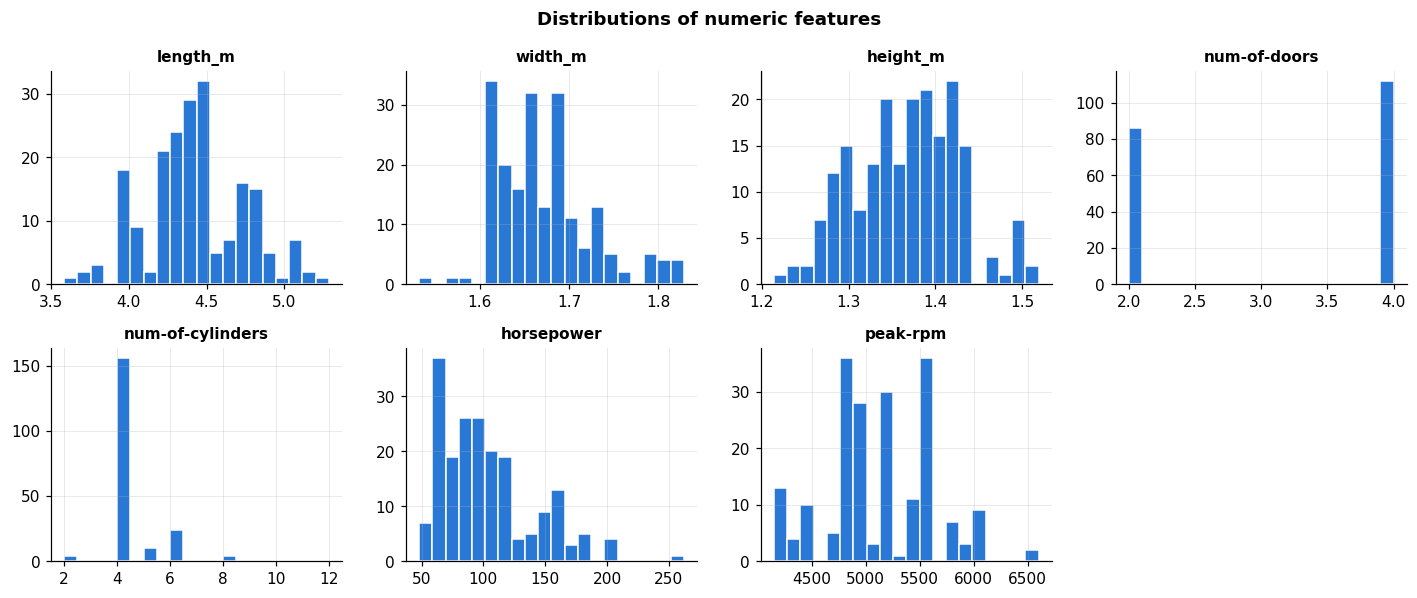

In [13]:
num_cols_raw = ["length_m", "width_m", "height_m", "num-of-doors", "num-of-cylinders",
                "horsepower", "peak-rpm"]

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, col in zip(axes.flat, num_cols_raw):
    ax.hist(df[col].dropna(), bins=20, color=BLUE, edgecolor="white")
    ax.set_title(col, fontsize=10)
axes.flat[-1].axis("off")   # seven features in an eight-panel grid; hide the empty panel
plt.suptitle("Distributions of numeric features", fontweight="bold")
plt.tight_layout(); plt.show()

**IQR rule.** The interquartile range is IQR = Q3 − Q1, the spread of the middle 50% of values. A value is flagged as an outlier if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR; these are the whisker limits of a box plot.

- It is a screening tool, not a deletion rule: flagged values are inspected and removed only if physically impossible or recording errors.
- It suits continuous variables only. For `num-of-cylinders`, where most cars have exactly 4, it flags every other count.

Further reading: [Interquartile range (Wikipedia)](https://en.wikipedia.org/wiki/Interquartile_range)

In [14]:
# Flag outliers with the 1.5*IQR rule
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

# Inspect the flagged cars before deciding: these are real high-power designs, not recording errors
df.loc[iqr_outliers(df["horsepower"]), ["make", "num-of-cylinders", "horsepower", "city-mpg"]]

,make,num-of-cylinders,horsepower,city-mpg
46,jaguar,12,262.0,13
101,nissan,6,200.0,17
122,porsche,6,207.0,17
123,porsche,6,207.0,17
124,porsche,6,207.0,17


The IQR rule flags five high-horsepower vehicles. They are valid high-performance models (Jaguar, Porsche, Nissan) and are retained.

Outliers are removed only when physically impossible or attributable to recording error.

### 3.2 Correlation Analysis
Correlations show which features relate to the target, which are redundant (collinear), and which are suspiciously strong.

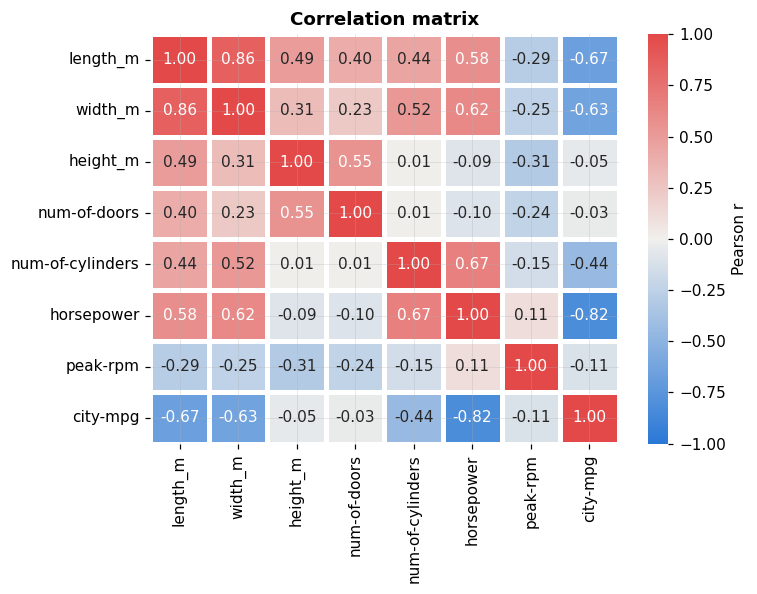

In [15]:
corr = df[num_cols_raw + ["city-mpg"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1,   # lock the scale to the full correlation range
            linewidths=2, linecolor="white", cbar_kws={"label": "Pearson r"})
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

- `horsepower` has the strongest correlation with `city-mpg` (r = −0.82).
- `length_m` and `width_m` are collinear (r = 0.86); regularisation (Ridge) mitigates this.
- `highway-mpg`, excluded in Section 1, is almost perfectly correlated with the target:

In [16]:
# Correlation of the target with highway-mpg (excluded as leakage)
df[["city-mpg", "highway-mpg"]].corr()

,city-mpg,highway-mpg
city-mpg,1.000,0.972
highway-mpg,0.972,1.000


### 3.3 Target Transformation
Linear models fit straight lines; a transformation can straighten a curved target–feature relationship.

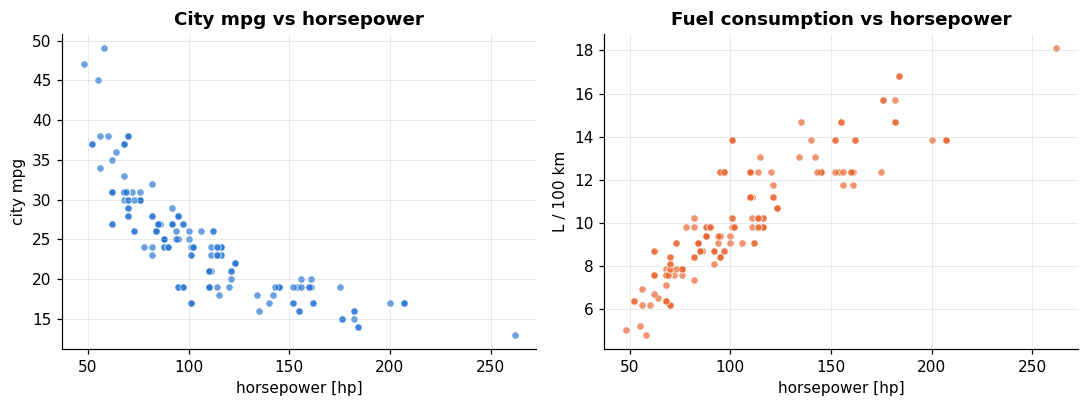

|r| with horsepower:  mpg = 0.82,  L/100km = 0.89


In [17]:
def mpg_to_l100km(mpg):
    # Converts US mpg to litres per 100 km. Applying it twice returns the input,
    # so the same function also converts L/100 km back to mpg.
    return 235.215 / mpg

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(df["horsepower"], df["city-mpg"], s=22, color=BLUE, alpha=0.7,
                edgecolor="white", linewidth=0.5)
axes[0].set(title="City mpg vs horsepower", xlabel="horsepower [hp]", ylabel="city mpg")
axes[1].scatter(df["horsepower"], mpg_to_l100km(df["city-mpg"]), s=22, color=ORANGE,
                alpha=0.7, edgecolor="white", linewidth=0.5)
axes[1].set(title="Fuel consumption vs horsepower", xlabel="horsepower [hp]", ylabel="L / 100 km")
plt.tight_layout(); plt.show()

r_mpg = df["horsepower"].corr(df["city-mpg"])
r_l100 = df["horsepower"].corr(mpg_to_l100km(df["city-mpg"]))
print(f"|r| with horsepower:  mpg = {abs(r_mpg):.2f},  L/100km = {abs(r_l100):.2f}")

Fuel consumption (L/100 km = 235.2 / mpg) is approximately linear in horsepower, whereas mpg (its reciprocal) is not. Linear models therefore predict L/100 km in Section 5; tree models do not need the transformation.

### 3.4 Categorical Features
Checks whether categories shift the target (worth encoding) and whether rare levels need grouping.

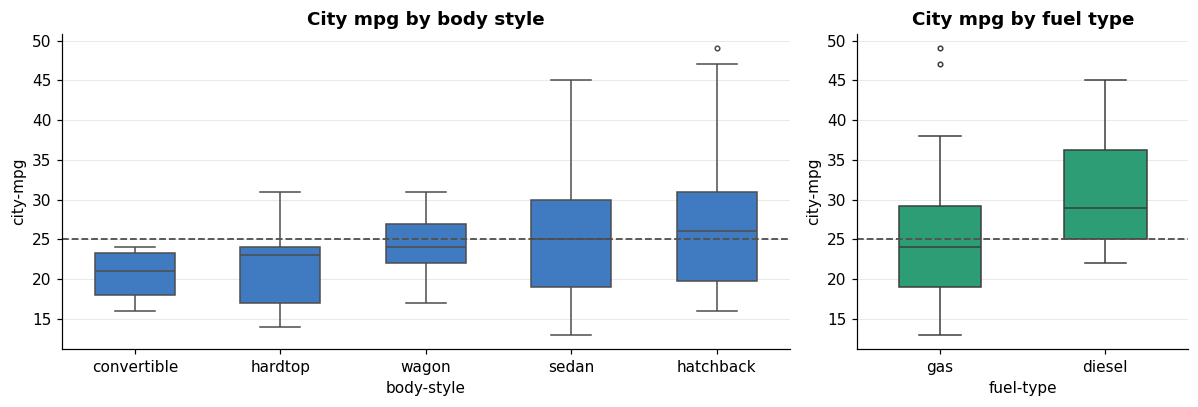

Least frequent makes:
{'saab': 6, 'porsche': 4, 'chevrolet': 3, 'alfa-romero': 3, 'jaguar': 3, 'isuzu': 2, 'renault': 2, 'mercury': 1}


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
order = df.groupby("body-style")["city-mpg"].median().sort_values().index   # low to high median mpg
sns.boxplot(data=df, x="body-style", y="city-mpg", order=order, color=BLUE,
            ax=axes[0], width=0.55, fliersize=3)
sns.boxplot(data=df, x="fuel-type", y="city-mpg", color=AQUA, ax=axes[1], width=0.5, fliersize=3)
for ax in axes:
    ax.axhline(SPEC_MPG, color=GRAY, ls="--", lw=1.2)
axes[0].set_title("City mpg by body style"); axes[1].set_title("City mpg by fuel type")
plt.tight_layout(); plt.show()

# Rare makes are grouped into one level by the encoder in Section 4.2 (min_frequency=5)
print("Least frequent makes:")
print(df["make"].value_counts().tail(8).to_dict())

- Diesel cars have a higher median `city-mpg` than petrol cars (29 vs 24), and body styles differ by up to 5 mpg; both are worth encoding.
- `make` has several brands with fewer than 5 cars, too few to learn from; Step 4 (Section 4.2) groups them into one *infrequent* level.

<a id="4-modelling-setup"></a>

## 4. Modelling Setup
### 4.1 Train/Test Split
All fitted operations (imputation, scaling, encoding, model training) use the training set only. A single stratified 80/20 split is shared by both tasks.

In [19]:
from sklearn.model_selection import train_test_split

df["meets_spec"] = (df["city-mpg"] >= SPEC_MPG).astype(int)

train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE,
    stratify=df["meets_spec"])   # keep the same share of cars that meet the spec in both sets

print(f"Train: {len(train_df)} cars | Test: {len(test_df)} cars")
print("Fraction meeting spec  -> train: %.2f  test: %.2f"
      % (train_df["meets_spec"].mean(), test_df["meets_spec"].mean()))

Train: 160 cars | Test: 40 cars
Fraction meeting spec  -> train: 0.49  test: 0.50


### 4.2 Preprocessing 
Each step is **fitted** on the training set (`fit`: learn values) and **applied** with those same values to the training set and the test set (`transform`). The test set never influences what is learned.

- **Step 1, feature selection:** keep only features known at the design stage (Section 1); categorical features are kept because they shift `city-mpg` (Section 3.4)
- **Step 2, imputation:** fill the ~1% missing values (Section 2.8); most models cannot handle `NaN`
- **Step 3, scaling:** standardise numeric features so their units do not bias regularised models
- **Step 4, encoding:** convert categories to 0/1 columns; rare makes (Section 3.4) share one column
- **Step 5, assembly:** join numeric and encoded columns into one matrix

In [20]:
# Step 1: feature selection
NUMERIC_FEATURES = ["length_m", "width_m", "height_m", "num-of-doors", "num-of-cylinders",
                    "horsepower", "peak-rpm"]
CATEGORICAL_FEATURES = ["make", "fuel-type", "body-style", "engine-location"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
# Deliberately excluded: 'price' (not known at design time), 'highway-mpg' (leakage),
# 'city-mpg' and 'meets_spec' (the targets)

X_train, X_test = train_df[FEATURES], test_df[FEATURES]
print("Numeric features:", len(NUMERIC_FEATURES), "| categorical features:", len(CATEGORICAL_FEATURES))

Numeric features: 7 | categorical features: 4


**Step 2: Imputation.** Numeric gaps are filled with the training **median** (robust to outliers); categorical gaps with the most frequent training level.

In [21]:
# Step 2: imputation
from sklearn.impute import SimpleImputer

# set_output(transform="pandas") returns DataFrames, so column names stay visible
num_imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
cat_imputer = SimpleImputer(strategy="most_frequent").set_output(transform="pandas")

num_imputer.fit(X_train[NUMERIC_FEATURES])       # learn one median per numeric column
cat_imputer.fit(X_train[CATEGORICAL_FEATURES])   # learn the most frequent level per categorical column

num_train = num_imputer.transform(X_train[NUMERIC_FEATURES])
num_test = num_imputer.transform(X_test[NUMERIC_FEATURES])     # filled with TRAINING medians
cat_train = cat_imputer.transform(X_train[CATEGORICAL_FEATURES])
cat_test = cat_imputer.transform(X_test[CATEGORICAL_FEATURES])

print("Missing numeric values in training set -> before:", int(X_train[NUMERIC_FEATURES].isna().sum().sum()),
      "| after:", int(num_train.isna().sum().sum()))

# Rows that had gaps: original value next to the imputed value
gap_cols = X_train[NUMERIC_FEATURES].columns[X_train[NUMERIC_FEATURES].isna().any()]
gap_rows = X_train[gap_cols].isna().any(axis=1)
pd.concat([X_train.loc[gap_rows, gap_cols].add_suffix(" (before)"),
           num_train.loc[gap_rows, gap_cols].add_suffix(" (after)")], axis=1)

Missing numeric values in training set -> before: 6 | after: 0


,num-of-doors (before),horsepower (before),peak-rpm (before),num-of-doors (after),horsepower (after),peak-rpm (after)
126,2.0,NaN,NaN,2.0,95.0,5050.0
26,NaN,102.0,5500.0,4.0,102.0,5500.0
125,4.0,NaN,NaN,4.0,95.0,5050.0
60,NaN,64.0,4650.0,4.0,64.0,4650.0


**Step 3: Scaling.** `StandardScaler` subtracts the training mean and divides by the training standard deviation, so every numeric feature has mean 0 and standard deviation 1 on the training set. Without it, regularised models (Ridge, logistic regression) would penalise features unequally because of their units (e.g. `peak-rpm` in thousands vs `height_m` around 1).

In [22]:
# Step 3: scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().set_output(transform="pandas")
scaler.fit(num_train)                              # learn mean and std per column
num_train_scaled = scaler.transform(num_train)
num_test_scaled = scaler.transform(num_test)       # scaled with the TRAINING mean and std

pd.DataFrame({
    "learned mean": scaler.mean_,
    "learned std": scaler.scale_,
    "train mean after": num_train_scaled.mean(),
    "train std after": num_train_scaled.std(ddof=0),
    "test mean after": num_test_scaled.mean(),     # close to, but not exactly, 0
}, index=NUMERIC_FEATURES).round(3) + 0.0          # round away floating-point noise (e.g. 2e-15 -> 0.0)

,learned mean,learned std,train mean after,train std after,test mean after
length_m,4.444,0.321,0.0,1.0,-0.296
width_m,1.676,0.056,0.0,1.0,-0.250
height_m,1.369,0.060,0.0,1.0,-0.267
num-of-doors,3.212,0.977,0.0,1.0,-0.371
num-of-cylinders,4.331,1.053,0.0,1.0,0.160
horsepower,103.081,36.236,0.0,1.0,0.023
peak-rpm,5098.125,496.043,0.0,1.0,0.170


**Step 4: One-hot encoding.** Each category level becomes a 0/1 column. Levels with fewer than 5 training rows share one *infrequent* column: a make with only 1–2 cars gives too little data to learn from. The threshold of 5 is a judgement call for 160 training cars.

In [23]:
# Step 4: one-hot encoding
from sklearn.preprocessing import OneHotEncoder

# Levels with fewer than 5 training rows share one "infrequent" column;
# levels not seen in training are assigned to that column at prediction time
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5,
                        sparse_output=False).set_output(transform="pandas")
encoder.fit(cat_train)                             # learn the levels of each categorical column
cat_train_encoded = encoder.transform(cat_train)
cat_test_encoded = encoder.transform(cat_test)

print("Categorical columns:", cat_train.shape[1], "-> 0/1 columns:", cat_train_encoded.shape[1])
print("'make' columns:", [c for c in cat_train_encoded.columns if c.startswith("make_")])

# Example: original body style next to its 0/1 columns
pd.concat([cat_train[["body-style"]], cat_train_encoded.filter(like="body-style_")], axis=1).head()

Categorical columns: 4 -> 0/1 columns: 25
'make' columns: ['make_audi', 'make_bmw', 'make_dodge', 'make_honda', 'make_mazda', 'make_mercedes-benz', 'make_mitsubishi', 'make_nissan', 'make_peugot', 'make_plymouth', 'make_saab', 'make_subaru', 'make_toyota', 'make_volkswagen', 'make_volvo', 'make_infrequent_sklearn']


,body-style,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,body-style_infrequent_sklearn
109,wagon,0.0,0.0,0.0,1.0,0.0
177,sedan,0.0,0.0,1.0,0.0,0.0
70,sedan,0.0,0.0,1.0,0.0,0.0
181,sedan,0.0,0.0,1.0,0.0,0.0
172,hatchback,0.0,1.0,0.0,0.0,0.0


**Step 5: Assembly.** Numeric and encoded columns are joined into the model-ready matrix. `prepare()` applies the fitted Steps 2–5 in order, so the test set and new designs are transformed with the same training statistics.

*Note:* the steps are fitted once on the whole training set, so cross-validation in Sections 5–6 is very slightly optimistic (validation folds contributed to the medians, means and category levels). The test set is unaffected. In production code, scikit-learn's `Pipeline` refits the steps inside every fold.

In [24]:
# Step 5: assembly
def prepare(X):
    # Apply the fitted Steps 2-4 to any data with the raw feature columns, then join the results
    num = scaler.transform(num_imputer.transform(X[NUMERIC_FEATURES]))
    cat = encoder.transform(cat_imputer.transform(X[CATEGORICAL_FEATURES]))
    return pd.concat([num, cat], axis=1)

X_train_prep = prepare(X_train)
X_test_prep = prepare(X_test)

print("Raw features:", X_train.shape[1], "-> model-ready features:", X_train_prep.shape[1])
print("Missing values left:", int(X_train_prep.isna().sum().sum()))
X_train_prep.head()

Raw features: 11 -> model-ready features: 32
Missing values left: 0


,length_m,width_m,height_m,num-of-doors,num-of-cylinders,horsepower,peak-rpm,make_audi,make_bmw,make_dodge,...,make_infrequent_sklearn,fuel-type_diesel,fuel-type_gas,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,body-style_infrequent_sklearn,engine-location_front,engine-location_infrequent_sklearn
109,1.893,1.094,1.194,0.806,-0.315,-0.223,-0.198,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
177,-0.258,-0.229,0.767,-1.241,-0.315,-1.410,-0.601,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
70,2.620,2.600,1.194,0.806,3.484,2.233,-1.206,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
181,-0.258,-0.229,0.767,0.806,-0.315,-0.499,0.306,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
172,0.051,0.228,-0.001,0.806,-0.315,-0.306,-1.811,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


<a id="5-regression-city-fuel-economy"></a>

## 5. Regression: City Fuel Economy
- **MAE:** mean absolute error (mpg)
- **RMSE:** root mean squared error (mpg); penalises large errors
- **R²:** fraction of variance explained

### 5.1 Model Comparison
5-fold cross-validation on the training set; the baseline predicts the training mean. A model is only useful if it clearly beats this baseline.

In [25]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

y_train_reg = train_df["city-mpg"]
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

REG_SCORING = {"MAE": "neg_mean_absolute_error",
               "RMSE": "neg_root_mean_squared_error",
               "R2": "r2"}

def cv_compare(models, X, y, cv, scoring):
    # Cross-validate each model; return one row per model with the mean and std of each metric across folds
    rows = []
    for name, model in models.items():
        res = cross_validate(model, X, y, cv=cv, scoring=scoring)
        row = {"model": name}
        for metric, scorer in scoring.items():
            vals = res[f"test_{metric}"]
            if scorer.startswith("neg_"):
                vals = -vals                       # error scorers return negative values; flip to positive errors
            row[metric] = vals.mean()
            row[metric + "_std"] = vals.std()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model")

def on_l100km(model):
    # Train the model on L/100 km; its predictions are converted back to mpg, so errors stay in mpg
    return TransformedTargetRegressor(regressor=model, func=mpg_to_l100km, inverse_func=mpg_to_l100km)

reg_models = {
    "Baseline (predict mean)":       DummyRegressor(),
    "Linear Regression":             LinearRegression(),
    "Linear Regression (L/100km)":   on_l100km(LinearRegression()),
    "Ridge (L/100km)":               on_l100km(Ridge(alpha=1.0)),
    "Random Forest":                 RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
}
reg_results = cv_compare(reg_models, X_train_prep, y_train_reg, cv_reg, REG_SCORING)
reg_results

,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std
model,,,,,,
Baseline (predict mean),5.234,0.496,6.658,0.363,-0.123,0.117
Linear Regression,2.536,0.165,3.351,0.394,0.706,0.082
Linear Regression (L/100km),2.267,0.220,3.081,0.440,0.757,0.059
Ridge (L/100km),2.118,0.194,2.853,0.348,0.792,0.047
Random Forest,1.664,0.341,2.483,0.481,0.832,0.072


Differences smaller than one standard deviation across folds should not be over-interpreted.

### 5.2 Hyperparameter Tuning
Default settings are rarely optimal; tuning inside cross-validation selects them without using the test set.

In [26]:
from sklearn.model_selection import GridSearchCV

ridge_search = GridSearchCV(
    on_l100km(Ridge()),
    # Parameter path: TransformedTargetRegressor ('regressor') -> alpha
    param_grid={"regressor__alpha": [0.01, 0.1, 1, 3, 10, 30, 100]},
    cv=cv_reg, scoring="neg_mean_absolute_error")
ridge_search.fit(X_train_prep, y_train_reg)

rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    param_grid={"max_depth": [None, 5, 10],
                "min_samples_leaf": [1, 2, 4],
                "max_features": [1.0, 0.5]},
    cv=cv_reg, scoring="neg_mean_absolute_error")
rf_search.fit(X_train_prep, y_train_reg)

# best_score_ is the negative MAE; the minus sign reports it as a positive error
print(f"Ridge (L/100km) best alpha: {ridge_search.best_params_}  CV MAE = {-ridge_search.best_score_:.2f} mpg")
print(f"Random Forest best params:  {rf_search.best_params_}  CV MAE = {-rf_search.best_score_:.2f} mpg")

Ridge (L/100km) best alpha: {'regressor__alpha': 10}  CV MAE = 1.98 mpg
Random Forest best params:  {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}  CV MAE = 1.63 mpg


In [27]:
# Choose using cross-validation scores only (no test data); the highest negative MAE is the lowest MAE
candidates = {"Ridge (L/100km)": ridge_search, "Random Forest": rf_search}
best_reg_name = max(candidates, key=lambda k: candidates[k].best_score_)
best_reg = candidates[best_reg_name].best_estimator_
print("Selected regression model:", best_reg_name)

Selected regression model: Random Forest


### 5.3 Test-Set Evaluation
The test set is evaluated once, after model selection.

In [28]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

y_test_reg = test_df["city-mpg"]
y_pred_reg = best_reg.predict(X_test_prep)

baseline_mae = mean_absolute_error(y_test_reg, np.full(len(y_test_reg), y_train_reg.mean()))   # predict the training mean
print(f"Test MAE  : {mean_absolute_error(y_test_reg, y_pred_reg):.2f} mpg   (baseline {baseline_mae:.2f} mpg)")
print(f"Test RMSE : {root_mean_squared_error(y_test_reg, y_pred_reg):.2f} mpg")
print(f"Test R²   : {r2_score(y_test_reg, y_pred_reg):.3f}")

Test MAE  : 1.26 mpg   (baseline 5.04 mpg)
Test RMSE : 1.90 mpg
Test R²   : 0.895


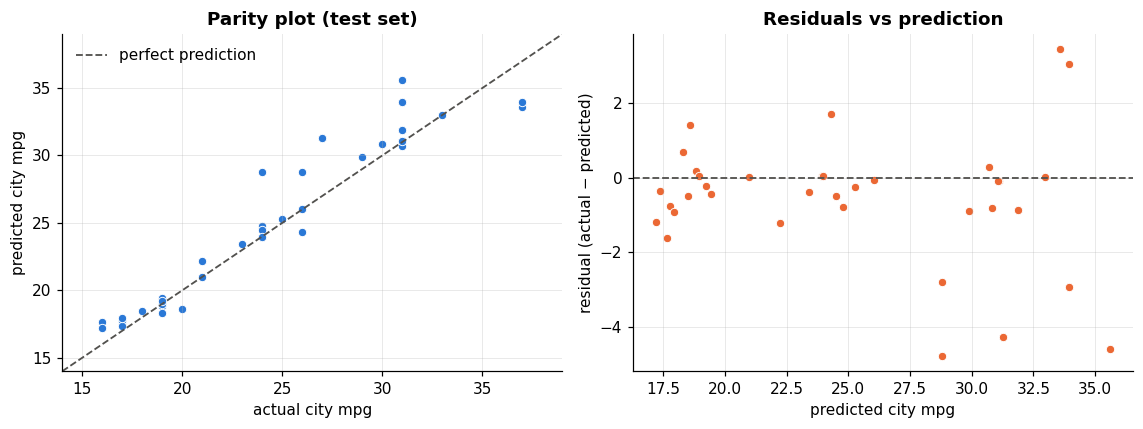

In [29]:
residuals = y_test_reg - y_pred_reg
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))

lims = [min(y_test_reg.min(), y_pred_reg.min()) - 2, max(y_test_reg.max(), y_pred_reg.max()) + 2]
axes[0].plot(lims, lims, color=GRAY, lw=1.2, ls="--", label="perfect prediction")
axes[0].scatter(y_test_reg, y_pred_reg, s=30, color=BLUE, edgecolor="white", linewidth=0.6)
axes[0].set(xlim=lims, ylim=lims, xlabel="actual city mpg", ylabel="predicted city mpg",
            title="Parity plot (test set)")
axes[0].legend(frameon=False)

axes[1].axhline(0, color=GRAY, lw=1.2, ls="--")
axes[1].scatter(y_pred_reg, residuals, s=30, color=ORANGE, edgecolor="white", linewidth=0.6)
axes[1].set(xlabel="predicted city mpg", ylabel="residual (actual − predicted)",
            title="Residuals vs prediction")
plt.tight_layout(); plt.show()

The test MAE of 1.26 mpg meets the success criterion (about 2 mpg, Section 1) and is four times better than the baseline.

Residuals should be unstructured around zero; increasing spread at high mpg indicates heteroscedasticity.

### 5.4 Permutation Importance
Increase in test MAE when each feature is randomly permuted. Shows which design inputs drive the prediction and confirms the model relies on sensible features.

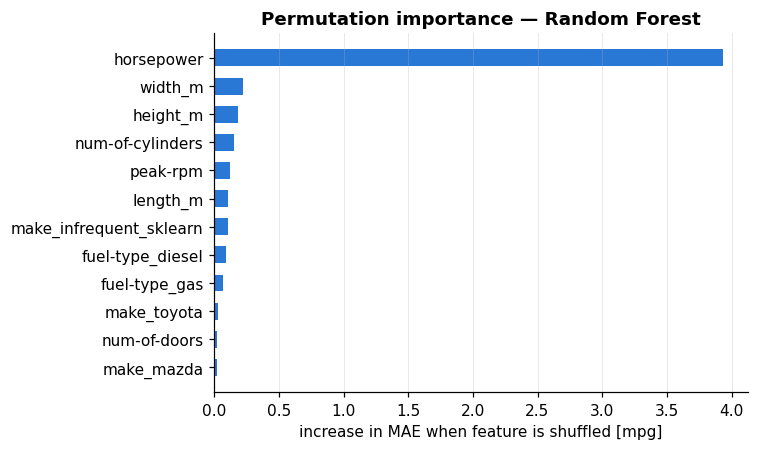

In [30]:
from sklearn.inspection import permutation_importance

# Importance = increase in test MAE when one column is randomly shuffled (30 repeats per column)
perm = permutation_importance(best_reg, X_test_prep, y_test_reg, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
imp = pd.Series(perm.importances_mean, index=X_test_prep.columns).sort_values().tail(12)   # 12 most important columns

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set(xlabel="increase in MAE when feature is shuffled [mpg]",
       title=f"Permutation importance — {best_reg_name}")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

<a id="6-classification-fuel-economy-specification"></a>

## 6. Classification: Fuel-Economy Specification
Target `meets_spec` = 1 if `city-mpg ≥ 25`. `city-mpg` and `highway-mpg` are excluded from the features.

In [31]:
y_train_clf = train_df["meets_spec"]
y_test_clf = test_df["meets_spec"]
print("Class balance (training set):")
print(y_train_clf.value_counts(normalize=True).rename({1: "meets spec (1)", 0: "fails spec (0)"}))

Class balance (training set):
meets_spec
fails spec (0)    0.506
meets spec (1)    0.494
Name: proportion, dtype: float64


- **Accuracy:** fraction of correct predictions
- **Precision:** fraction of predicted passes that truly pass
- **Recall:** fraction of true passes detected
- **F1:** harmonic mean of precision and recall
- **ROC AUC:** ranking quality across all thresholds

### 6.1 Model Comparison
Classes are balanced; stratified 5-fold cross-validation is used. For imbalanced data, accuracy alone is misleading.

In [32]:
from sklearn.model_selection import StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import warnings
from sklearn.exceptions import UndefinedMetricWarning
# The baseline never predicts class 1, so its precision is 0/0; sklearn reports 0 and warns. Hide that warning.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

CLF_SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
               "F1": "f1", "ROC_AUC": "roc_auc"}
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # each fold keeps the class ratio

clf_models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),   # always predict the majority class
    "Logistic Regression":      LogisticRegression(max_iter=1000),
    "Random Forest":            RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}
clf_results = cv_compare(clf_models, X_train_prep, y_train_clf, cv_clf, CLF_SCORING)
clf_results[["accuracy", "precision", "recall", "F1", "ROC_AUC", "ROC_AUC_std"]]

,accuracy,precision,recall,F1,ROC_AUC,ROC_AUC_std
model,,,,,,
Baseline (most frequent),0.506,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.887,0.885,0.899,0.888,0.973,0.014
Random Forest,0.938,0.940,0.938,0.936,0.989,0.008


The baseline reaches 50% accuracy with zero precision and recall.

### 6.2 Hyperparameter Tuning
As in Section 5.2, settings are tuned by cross-validation on the training set only.

In [33]:
logreg_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    # C = inverse regularisation strength (smaller C = simpler model).
    # ROC AUC measures ranking quality and does not depend on the 0.5 threshold.
    param_grid={"C": [0.01, 0.1, 0.3, 1, 3, 10, 100]},
    cv=cv_clf, scoring="roc_auc")
logreg_search.fit(X_train_prep, y_train_clf)

rf_clf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    param_grid={"max_depth": [None, 5], "min_samples_leaf": [1, 3]},
    cv=cv_clf, scoring="roc_auc")
rf_clf_search.fit(X_train_prep, y_train_clf)

print(f"Logistic Regression best {logreg_search.best_params_}  CV AUC = {logreg_search.best_score_:.3f}")
print(f"Random Forest best {rf_clf_search.best_params_}  CV AUC = {rf_clf_search.best_score_:.3f}")

clf_candidates = {"Logistic Regression": logreg_search, "Random Forest": rf_clf_search}
best_clf_name = max(clf_candidates, key=lambda k: clf_candidates[k].best_score_)
best_clf = clf_candidates[best_clf_name].best_estimator_
print("Selected classification model:", best_clf_name)

Logistic Regression best {'C': 100}  CV AUC = 0.980
Random Forest best {'max_depth': None, 'min_samples_leaf': 1}  CV AUC = 0.989
Selected classification model: Random Forest


### 6.3 Test-Set Evaluation
The test set is used once, after model selection, for an unbiased estimate on unseen designs.

In [34]:
from sklearn.metrics import classification_report

y_pred_clf = best_clf.predict(X_test_prep)
print(classification_report(y_test_clf, y_pred_clf, target_names=["fails spec", "meets spec"]))

              precision    recall  f1-score   support

  fails spec       1.00      0.90      0.95        20
  meets spec       0.91      1.00      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



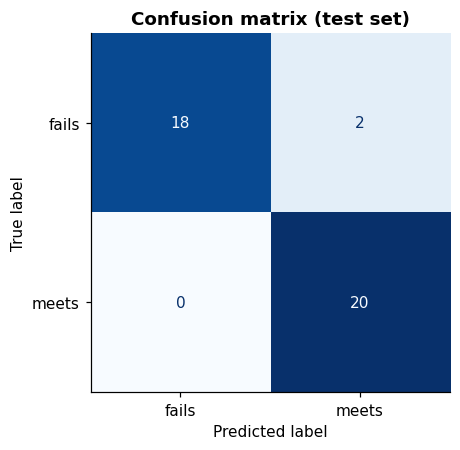

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test_clf, y_pred_clf, display_labels=["fails", "meets"], cmap="Blues",
    colorbar=False, ax=ax)
ax.set_title("Confusion matrix (test set)"); ax.grid(False)
plt.tight_layout(); plt.show()

On the test set, 91% of predicted passes truly pass (precision) and every passing design is found (recall 1.00); the confusion matrix shows the two failing designs that were wrongly passed.

*Decision threshold.* A false pass (prototype fails certification) is typically costlier than a false fail. Raising the probability threshold above the default 0.5 increases precision at the expense of recall; in practice the threshold is chosen from cross-validated training predictions, never from the test set.

<a id="7-model-persistence-and-inference"></a>

## 7. Model Persistence and Inference
The fitted preprocessing steps and the final models are saved to disk and applied to a new design concept supplied in the units of the cleaned data.

- **Persistence:** save the fitted preprocessing steps together with the model; the model alone cannot read raw inputs
- **Inference:** new inputs must have the same columns and units as the training data

In [36]:
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
# Save the fitted preprocessing steps together with the models: the models expect prepared input
joblib.dump({"num_imputer": num_imputer, "scaler": scaler,
             "cat_imputer": cat_imputer, "encoder": encoder,
             "regressor": best_reg, "classifier": best_clf},
            MODEL_DIR / "fuel_economy_models.joblib")

# New design concept in the same units and formats as the cleaned training data
# (dimensions in metres, counts as integers)
concept = pd.DataFrame([{
    "make": "toyota", "fuel-type": "gas", "body-style": "sedan", "engine-location": "front",
    "num-of-doors": 4, "num-of-cylinders": 4, "horsepower": 95, "peak-rpm": 5200,
    "length_m": 4.40, "width_m": 1.66, "height_m": 1.38,
}])
concept = concept[FEATURES]   # same column order as the training data

# Apply the saved Steps 2-5 in the same order as in Section 4.2.
# Loading a model that uses mpg_to_l100km requires that function to be defined.
saved = joblib.load(MODEL_DIR / "fuel_economy_models.joblib")
num = saved["scaler"].transform(saved["num_imputer"].transform(concept[NUMERIC_FEATURES]))
cat = saved["encoder"].transform(saved["cat_imputer"].transform(concept[CATEGORICAL_FEATURES]))
concept_prep = pd.concat([num, cat], axis=1)

print(f"Predicted city fuel economy         : {saved['regressor'].predict(concept_prep)[0]:.1f} mpg")
print(f"Probability of meeting {SPEC_MPG} mpg spec : {saved['classifier'].predict_proba(concept_prep)[0, 1]:.2f}")

Predicted city fuel economy         : 25.6 mpg
Probability of meeting 25 mpg spec : 0.83


<a id="8-apply-to-other-datasets"></a>

## 8. Apply to Other Datasets
Follow the same steps as Sections 1–7 on one of the datasets below. The last column lists what needs attention during cleaning and preprocessing.

| Task | Dataset | Target | Preprocessing considerations |
|---|---|---|---|
| Regression | `Regression/FuelConsumptionCo2.csv` | `CO2EMISSIONS` | `MODELYEAR` is constant and `MODEL` is a near-unique identifier; `FUELCONSUMPTION_*` columns leak the target for a design-stage model |
| Regression | `Regression/kc_house_data.csv` | `price` | `id` column; `date` needs parsing; `zipcode` is categorical; `yr_renovated = 0` means never renovated; strongly skewed target; 21,613 rows (tuning is slow) |
| Regression | `Regression/manhattan_Housing.csv` | `rent` | `rental_id` column; `borough` is constant; `neighborhood` has 32 levels; `bedrooms = 0` is a studio (valid), unlike `bathrooms = 0`; skewed target |
| Classification | `Classification/diabetes.csv` | `Outcome` | Zeros denote missing data in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`; mild class imbalance (35%) |
| Classification | `Classification/titanic.csv` | `survived` | Missing `age`, `cabin` (77%) and `embarked`; `name` and `ticket` are identifiers; `sex`, `embarked`, `pclass` are categorical |
| Classification | `Classification/Orange_Telecom_Churn_Data.csv` | `churned` | `phone_number` is an identifier; each `*_charge` column duplicates its `*_minutes` column (r = 1.0); class imbalance (14%) |

<a id="summary"></a>

## Summary
- Most modelling errors arise before model fitting; data leakage is the most consequential.
- Fit preprocessing on the training set only and apply the same fitted steps to test data and new inputs.
- Compare against a baseline, select models by cross-validation, and evaluate on the test set once.
- Domain knowledge (units, plausibility, error costs) informs every step.